Name: Mingze Geng

Github Username: Mingze88   

USC ID: 1418612987




In [52]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display, Markdown
from sklearn.tree import DecisionTreeClassifier, plot_tree, _tree
from sklearn.model_selection import KFold, StratifiedKFold, GridSearchCV, cross_val_score
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.decomposition import PCA
from sklearn.metrics import mean_squared_error, accuracy_score
from xgboost import XGBRegressor
def data_path(name):
    return Path(name)

## 1.
### (a)

In [54]:
diagnosis_columns = ['temperature', 'nausea', 'lumbar_pain', 'urine_pushing',
                     'micturition_pain', 'urethra_burning',
                     'bladder_inflammation', 'renal_nephritis']

diagnosis = pd.read_csv(data_path('diagnosis.data'), sep='\t', encoding='utf-16',
                        decimal=',', header=None, names=diagnosis_columns)
for col in diagnosis_columns[1:]:
    diagnosis[col] = diagnosis[col].map({'no': 0, 'yes': 1})
assert diagnosis.shape == (120, 8)
assert diagnosis.notna().all().all()
X_d = diagnosis.iloc[:, :6]
y_d = diagnosis['bladder_inflammation'].astype(str) + ',' + diagnosis['renal_nephritis'].astype(str)
print('Shape:', diagnosis.shape)
print('Classes: (bladder inflammation, renal nephritis), 0 = no, 1 = yes')
display(y_d.value_counts().rename_axis('Diagnosis pair').to_frame('Count'))

Shape: (120, 8)
Classes: (bladder inflammation, renal nephritis), 0 = no, 1 = yes


,Count
Diagnosis pair,
"1,0",40
"0,1",31
"0,0",30
"1,1",19


### (b) 

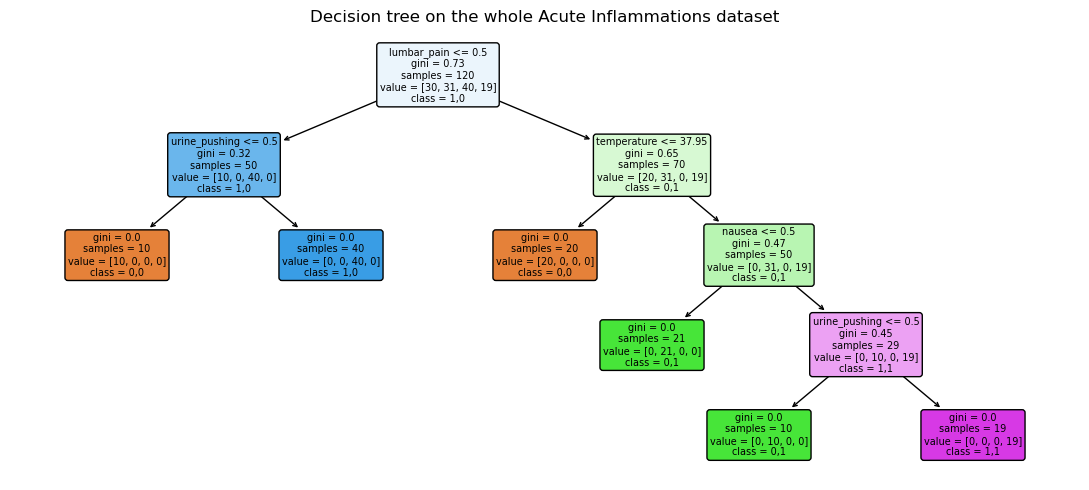

Depth: 4 | Leaves: 6
Training accuracy: 1.0


In [56]:
tree = DecisionTreeClassifier(random_state=42)
tree.fit(X_d, y_d)
def show_tree(model, title):
    plt.figure(figsize=(11, 5))
    plot_tree(model, feature_names=list(X_d.columns), class_names=list(model.classes_),
              filled=True, rounded=True, precision=2, fontsize=7)
    plt.title(title)
    plt.tight_layout()
    plt.show()
show_tree(tree, 'Decision tree on the whole Acute Inflammations dataset')
print('Depth:', tree.get_depth(), '| Leaves:', tree.get_n_leaves())
print('Training accuracy:', accuracy_score(y_d, tree.predict(X_d)))

### (c) 


In [58]:
def print_rules(model, feature_names):
    t = model.tree_

    def visit(node, rules):
        if t.children_left[node] == -1:
            label = model.classes_[t.value[node][0].argmax()]
            print(f"IF {' AND '.join(rules)} THEN diagnosis = ({label})")
            return

        name = feature_names[t.feature[node]]
        cutoff = t.threshold[node]
        visit(t.children_left[node], rules + [f"{name} <= {cutoff:.2f}"])
        visit(t.children_right[node], rules + [f"{name} > {cutoff:.2f}"])

    visit(0, [])

print_rules(tree, list(X_d.columns))


IF lumbar_pain <= 0.50 AND urine_pushing <= 0.50 THEN diagnosis = (0,0)
IF lumbar_pain <= 0.50 AND urine_pushing > 0.50 THEN diagnosis = (1,0)
IF lumbar_pain > 0.50 AND temperature <= 37.95 THEN diagnosis = (0,0)
IF lumbar_pain > 0.50 AND temperature > 37.95 AND nausea <= 0.50 THEN diagnosis = (0,1)
IF lumbar_pain > 0.50 AND temperature > 37.95 AND nausea > 0.50 AND urine_pushing <= 0.50 THEN diagnosis = (0,1)
IF lumbar_pain > 0.50 AND temperature > 37.95 AND nausea > 0.50 AND urine_pushing > 0.50 THEN diagnosis = (1,1)


### (d) 

,alpha,CV accuracy,leaves
0,0.000000,0.991667,6
1,0.098167,0.858333,4
2,0.133333,0.758333,3
3,0.182000,0.666667,2
4,0.222917,0.483333,1


Chosen alpha: 0.09816666666666667


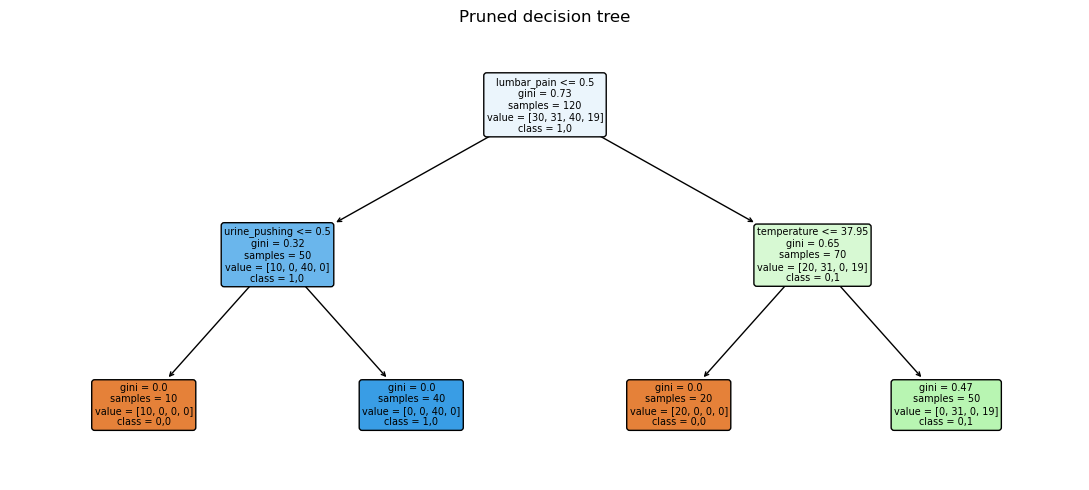

IF lumbar_pain <= 0.50 AND urine_pushing <= 0.50 THEN diagnosis = (0,0)
IF lumbar_pain <= 0.50 AND urine_pushing > 0.50 THEN diagnosis = (1,0)
IF lumbar_pain > 0.50 AND temperature <= 37.95 THEN diagnosis = (0,0)
IF lumbar_pain > 0.50 AND temperature > 37.95 THEN diagnosis = (0,1)


In [60]:
cv = StratifiedKFold(5, shuffle=True, random_state=42)
alphas = np.unique(tree.cost_complexity_pruning_path(X_d, y_d).ccp_alphas)
rows = []

for a in alphas:
    model = DecisionTreeClassifier(ccp_alpha=a, random_state=42)
    score = cross_val_score(model, X_d, y_d, cv=cv).mean()
    model.fit(X_d, y_d)
    rows.append([a, score, model.get_n_leaves()])

results = pd.DataFrame(rows, columns=['alpha', 'CV accuracy', 'leaves'])
smaller = results[results.leaves < tree.get_n_leaves()]
best = smaller.sort_values(
    ['CV accuracy', 'leaves'], ascending=[False, True]
).iloc[0]

pruned_tree = DecisionTreeClassifier(
    ccp_alpha=best.alpha, random_state=42
).fit(X_d, y_d)

display(results)
print('Chosen alpha:', best.alpha)
show_tree(pruned_tree, 'Pruned decision tree')
print_rules(pruned_tree, list(X_d.columns))

Pruning reduces the tree from 6 leaves to 4, but cross-validation accuracy decreases from 99.17% to 85.83%.

## 2. 
### (a) Load and split

In [62]:
columns = [line.split()[1]
           for line in Path('communities.names').read_text().splitlines()
           if line.startswith('@attribute')]

crime = pd.read_csv('communities.data', names=columns, na_values='?')
train, test = crime.iloc[:1495], crime.iloc[1495:]
print('Train:', train.shape, 'Test:', test.shape)

Train: (1495, 128) Test: (499, 128)


### (b) 

In [64]:
drop = ['state', 'county', 'community', 'communityname', 'fold',
        'ViolentCrimesPerPop']

X_train, X_test = train.drop(columns=drop), test.drop(columns=drop)
y_train, y_test = train.iloc[:, -1], test.iloc[:, -1]

imputer = SimpleImputer(strategy='median')
X_train_imp = pd.DataFrame(imputer.fit_transform(X_train), columns=X_train.columns)
X_test_imp = pd.DataFrame(imputer.transform(X_test), columns=X_test.columns)

print('Missing values:', X_train_imp.isna().sum().sum(),
      X_test_imp.isna().sum().sum())

Missing values: 0 0


### (c)


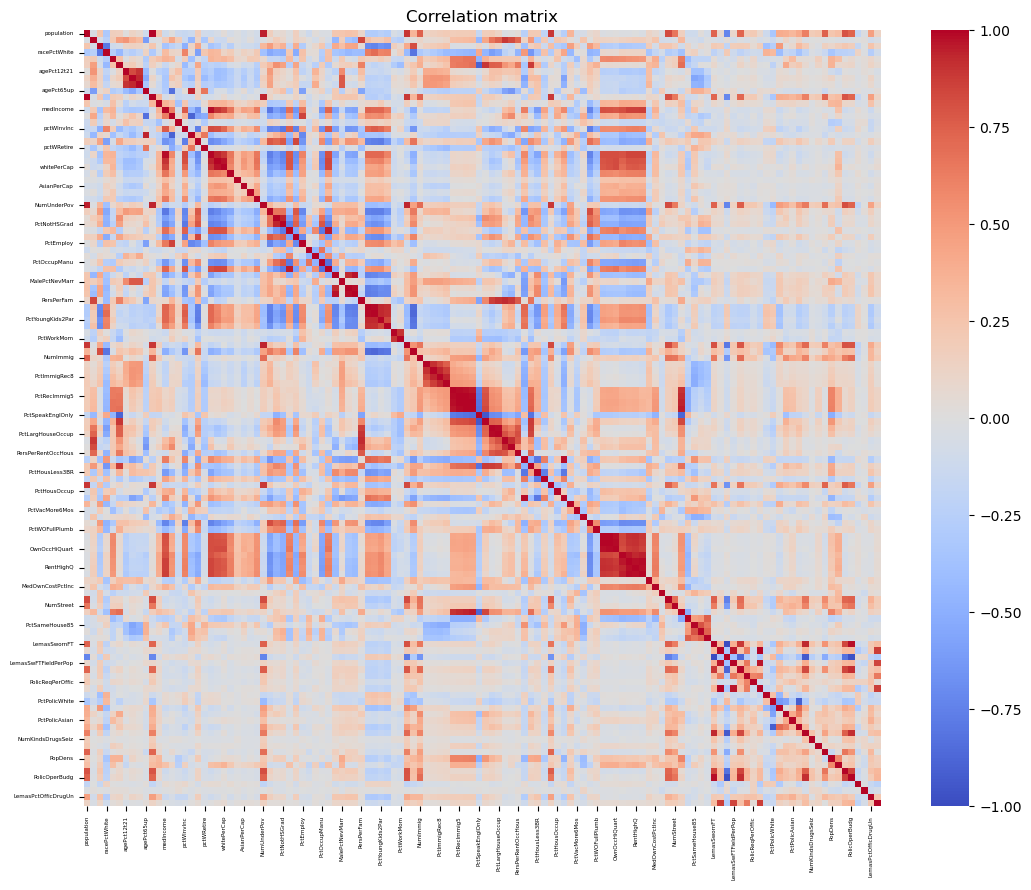

In [66]:
plt.figure(figsize=(11, 9))
sns.heatmap(X_train_imp.corr(), cmap='coolwarm', vmin=-1, vmax=1)
plt.xticks(fontsize=4)
plt.yticks(fontsize=4)
plt.title('Correlation matrix')
plt.tight_layout()
plt.show()

### (d) 


In [68]:
cv = X_train_imp.std(ddof=1) / X_train_imp.mean().replace(0, np.nan)
cv_table = cv.sort_values(ascending=False).to_frame('CV')

items = [f'{name}: {value:.3f}' for name, value in cv_table.CV.items()]
items += [''] * (-len(items) % 4)
print(pd.DataFrame(np.array(items).reshape(4, -1).T).to_string(index=False, header=False))

      PctPolicAsian: 5.527      OwnOccMedVal: 0.889          PctOccupManu: 0.516       PctHousLess3BR: 0.344
          NumStreet: 4.293     OwnOccHiQuart: 0.884           PctEmplManu: 0.514    MedRentPctHousInc: 0.343
      NumInShelters: 3.471           PopDens: 0.864          PctImmigRec8: 0.505  PctWorkMomYoungKids: 0.341
           NumIlleg: 3.059    OwnOccLowQuart: 0.860           agePct16t24: 0.500     PolicAveOTWorked: 0.336
           NumImmig: 2.927    PctWOFullPlumb: 0.843            HispPerCap: 0.484     PctBornSameState: 0.336
LemasPctOfficDrugUn: 2.553      indianPerCap: 0.818    PersPerRentOccHous: 0.474        PctHousOwnOcc: 0.336
        NumUnderPov: 2.342          MedNumBR: 0.814        MedYrHousBuilt: 0.471           PctWorkMom: 0.336
       LemasSwornFT: 2.248     PctPolicBlack: 0.776 MedOwnCostPctIncNoMtg: 0.470  LemasGangUnitDeploy: 0.335
         population: 2.241 PctLargHouseOccup: 0.763         PctImmigRec10: 0.458          PctKids2Par: 0.335
          numbUrban

### (e) 


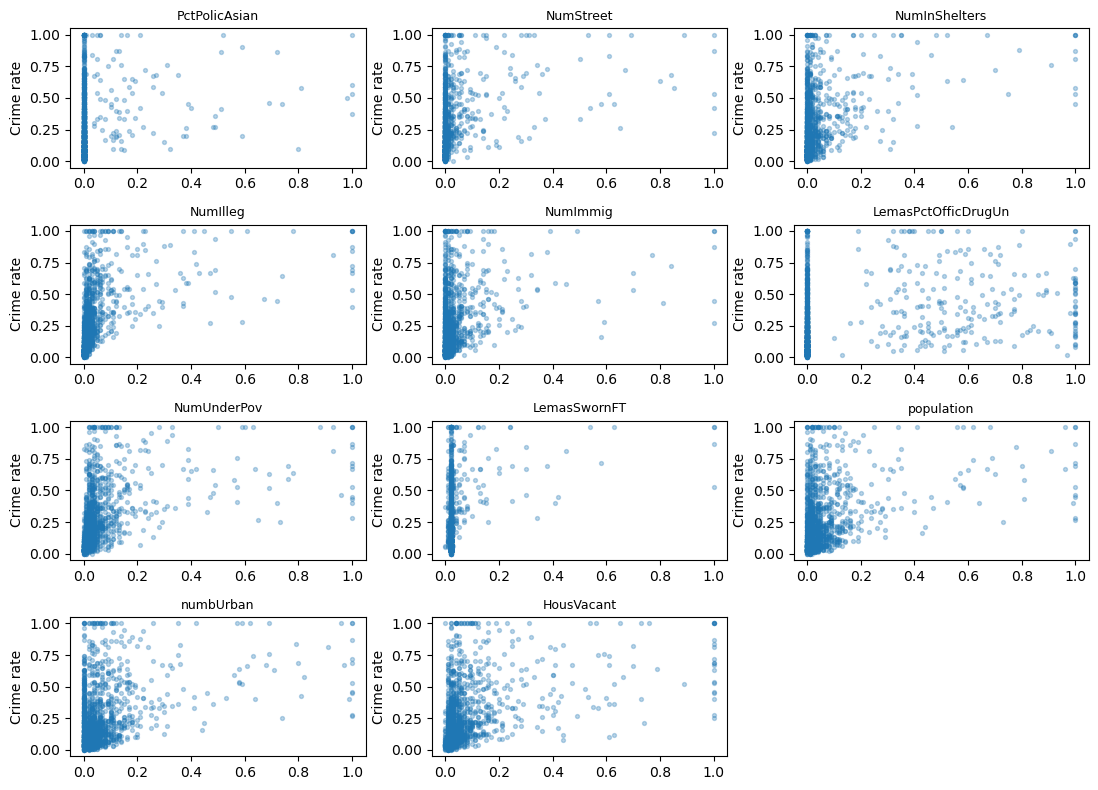

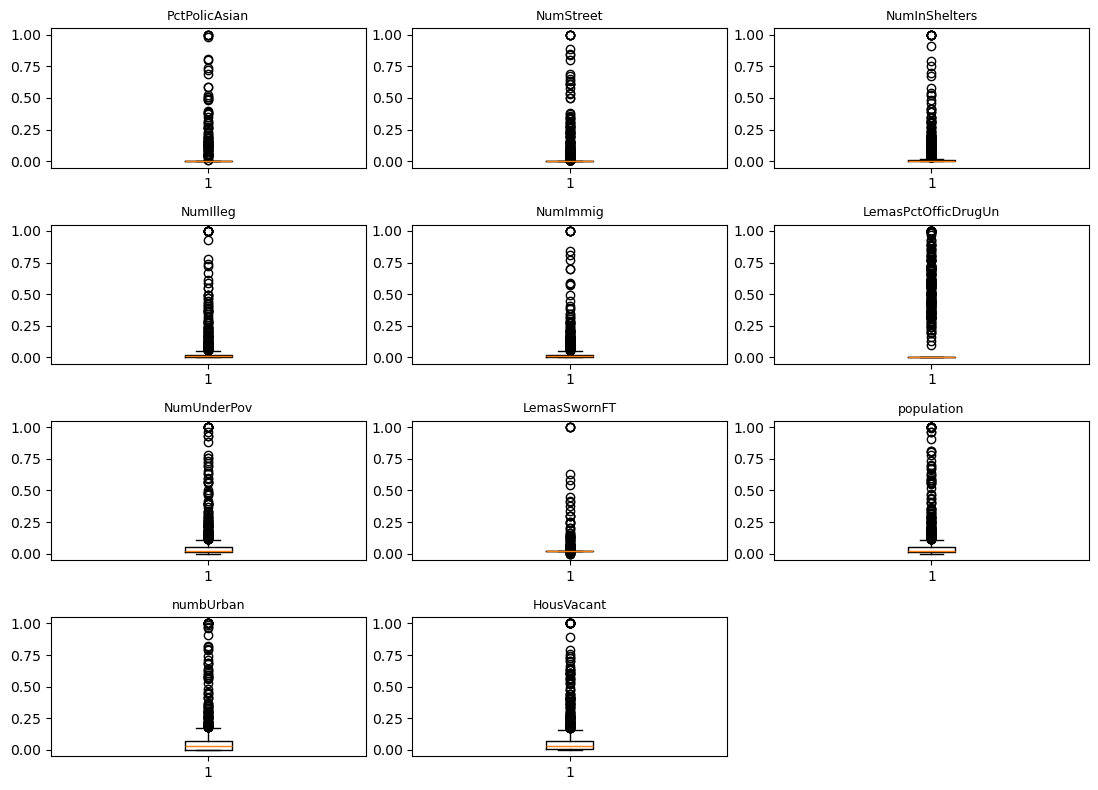

In [70]:
top_features = cv_table.head(11).index

for kind in ['scatter', 'box']:
    fig, axes = plt.subplots(4, 3, figsize=(11, 8))
    for ax, name in zip(axes.flat, top_features):
        if kind == 'scatter':
            ax.scatter(X_train_imp[name], y_train, s=8, alpha=0.3)
            ax.set_ylabel('Crime rate')
        else:
            ax.boxplot(X_train_imp[name])
        ax.set_title(name, fontsize=9)
    axes.flat[-1].axis('off')
    plt.tight_layout()
    plt.show()

The plots show skew, outliers, and possible associations. They cannot establish statistical significance or account for other predictors. High CV means high relative variability, not necessarily high predictive importance.

### (f) 

In [73]:
cv5 = KFold(5, shuffle=True, random_state=42)
results = []

def report_model(name, model):
    mse = mean_squared_error(y_test, model.predict(X_test))
    results.append({'Model': name, 'Test MSE': mse})
    print(name, 'Test MSE:', round(mse, 6))

def tune(steps, grid):
    pipe = Pipeline([('imputer', SimpleImputer(strategy='median'))] + steps)
    search = GridSearchCV(pipe, grid, cv=cv5, scoring='neg_mean_squared_error')
    return search.fit(X_train, y_train)

ols = Pipeline([('imputer', SimpleImputer(strategy='median')),
                ('model', LinearRegression())])
ols.fit(X_train, y_train)
report_model('Least squares', ols)

Least squares Test MSE: 0.017966


### (g) 


In [75]:
ridge = tune([('model', Ridge())],
             {'model__alpha': np.logspace(-4, 4, 41)})
print('Lambda:', ridge.best_params_['model__alpha'])
report_model('Ridge', ridge)

Lambda: 3.9810717055349776
Ridge Test MSE: 0.017454


### (h) 


In [77]:
import textwrap

for scaled in [False, True]:
    name = 'Standardized LASSO' if scaled else 'LASSO'
    steps = [('scaler', StandardScaler())] if scaled else []
    steps += [('model', Lasso(max_iter=100000, tol=1e-6))]
    model = tune(steps, {'model__alpha': np.logspace(-5, 0, 41)})

    print('\nLambda:', model.best_params_['model__alpha'])
    report_model(name, model)
    coef = model.best_estimator_.named_steps['model'].coef_
    selected = X_train.columns[coef != 0]
    print('Selected variables:', len(selected))
    print(textwrap.fill(', '.join(selected), width=100))


Lambda: 0.0001333521432163324
LASSO Test MSE: 0.017604
Selected variables: 76
racepctblack, racePctAsian, agePct12t21, agePct12t29, pctUrban, pctWWage, pctWFarmSelf, pctWInvInc,
pctWSocSec, pctWPubAsst, pctWRetire, whitePerCap, blackPerCap, indianPerCap, AsianPerCap,
OtherPerCap, HispPerCap, PctPopUnderPov, PctLess9thGrade, PctEmploy, PctEmplManu, PctOccupManu,
MalePctDivorce, MalePctNevMarr, FemalePctDiv, PctKids2Par, PctYoungKids2Par, PctTeen2Par,
PctWorkMom, NumIlleg, PctIlleg, NumImmig, PctImmigRecent, PctImmigRec5, PctImmigRec10,
PctRecImmig10, PctNotSpeakEnglWell, PctLargHouseOccup, PersPerOccupHous, PctPersOwnOccup,
PctPersDenseHous, PctHousLess3BR, MedNumBR, HousVacant, PctHousOccup, PctVacantBoarded,
PctVacMore6Mos, MedYrHousBuilt, PctHousNoPhone, PctWOFullPlumb, OwnOccLowQuart, RentLowQ, MedRent,
MedRentPctHousInc, MedOwnCostPctInc, MedOwnCostPctIncNoMtg, NumInShelters, NumStreet,
PctForeignBorn, PctBornSameState, PctSameCity85, LemasSwFTFieldPerPop, PolicReqPerOffic,
Racial

LASSO without standardization has a slightly lower test MSE (0.017604) than standardized LASSO (0.017748). They select 76 and 75 variables, respectively.

### (i) 

In [79]:
pcr = tune([('scaler', StandardScaler()),
            ('pca', PCA(svd_solver='full')),
            ('model', LinearRegression())],
           {'pca__n_components': range(1, X_train.shape[1] + 1)})

print('Chosen M:', pcr.best_params_['pca__n_components'])
report_model('PCR', pcr)

Chosen M: 60
PCR Test MSE: 0.01835


### (j)

In [81]:
boost = tune(
    [('model', XGBRegressor(
        objective='reg:squarederror', n_estimators=300,
        max_depth=3, learning_rate=0.05, tree_method='hist',
        random_state=42, n_jobs=1))],
    {'model__reg_alpha': [0, 0.001, 0.01, 0.1, 0.5, 1, 2, 5, 10, 50, 100]}
)

print('Chosen alpha:', boost.best_params_['model__reg_alpha'])
report_model('XGBoost', boost)

Chosen alpha: 0.1
XGBoost Test MSE: 0.016422


In [82]:
comparison = pd.DataFrame(results)
display(comparison)
best_test = comparison.loc[comparison['Test MSE'].idxmin()]
print(f"{best_test['Model']} has the lowest test MSE: {best_test['Test MSE']:.6f}.")

,Model,Test MSE
0,Least squares,0.017966
1,Ridge,0.017454
2,LASSO,0.017604
3,Standardized LASSO,0.017748
4,PCR,0.018350
5,XGBoost,0.016422


XGBoost has the lowest test MSE: 0.016422.
